# Task 4: High-Imbalance Clinical Disease Predictor Pipeline

## Objective
Build an end-to-end classification system to detect malignant (cancerous) tumours
from the imbalanced Breast Cancer Wisconsin (UCI) dataset. Handle class imbalance
using SMOTE and class weighting, tune SVM, Random Forest and XGBoost models with
5-fold cross-validation, and maximise Recall (sensitivity) so that as few cancer
cases as possible are missed.

## Import Libraries

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, RocCurveDisplay)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

print("Libraries imported successfully")

Libraries imported successfully


## Dataset load karein

In [8]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

# sklearn mein 0 = malignant hota hai. Hum ulta kar rahe hain taake 1 = disease (malignant)
y = pd.Series(1 - data.target, name='malignant')

print("Shape:", X.shape)
X.head()

Shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Data exploration aur imbalance check


In [9]:
X.info()
print("\nMissing values:", X.isnull().sum().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

malignant
0    357
1    212
Name: count, dtype: int64
Minority class (Malignant): 37.3%


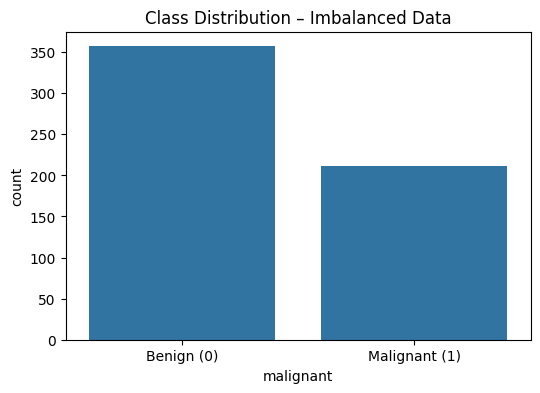

In [10]:
counts = y.value_counts()
print(counts)
print(f"Minority class (Malignant): {y.mean()*100:.1f}%")

plt.figure(figsize=(6,4))
sns.countplot(x=y)
plt.xticks([0,1], ['Benign (0)', 'Malignant (1)'])
plt.title('Class Distribution – Imbalanced Data')
plt.show()

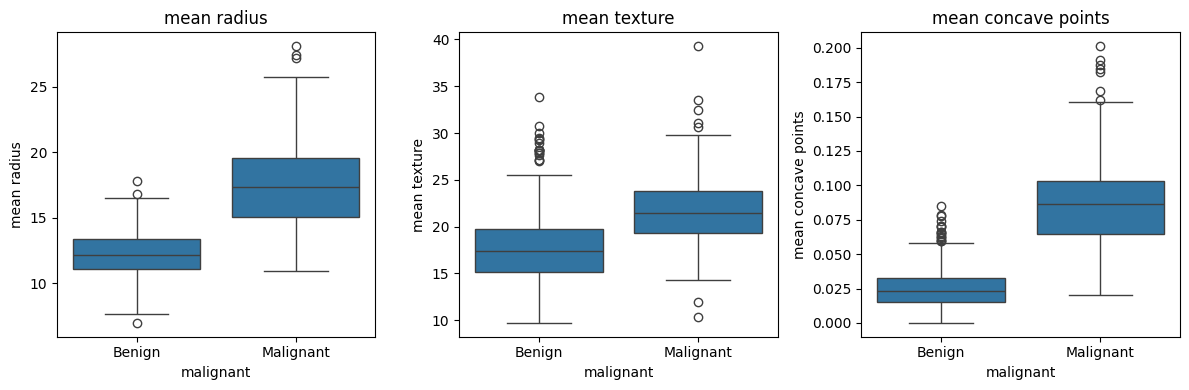

In [11]:
# Top features difference (EDA)
plt.figure(figsize=(12,4))
for i, col in enumerate(['mean radius', 'mean texture', 'mean concave points']):
    plt.subplot(1, 3, i+1)
    sns.boxplot(x=y, y=X[col])
    plt.xticks([0,1], ['Benign', 'Malignant'])
    plt.title(col)
plt.tight_layout()
plt.show()

## Train/Test Split (stratified)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Malignant % in train:", round(y_train.mean()*100, 1))
print("Malignant % in test :", round(y_test.mean()*100, 1))

Train: (455, 30)  Test: (114, 30)
Malignant % in train: 37.4
Malignant % in test : 36.8


## Baseline model

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=42))
])
base_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='recall')
print("Baseline CV Recall scores:", base_scores.round(3))
print("Baseline Mean Recall:", round(base_scores.mean(), 3))

Baseline CV Recall scores: [0.912 1.    0.882 0.971 0.941]
Baseline Mean Recall: 0.941


## leanr and show SMOTE 

In [14]:
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE :", pd.Series(y_sm).value_counts().to_dict())

Before SMOTE: {0: 285, 1: 170}
After SMOTE : {1: 285, 0: 285}


## tune the models 

In [15]:
models = {
    'SVM': (SVC(probability=True, random_state=42),
            {'clf__C': [0.1, 1, 10],
             'clf__kernel': ['linear', 'rbf'],
             'clf__gamma': ['scale', 0.01]}),

    'Random Forest': (RandomForestClassifier(random_state=42),
            {'clf__n_estimators': [100, 300],
             'clf__max_depth': [None, 5, 10],
             'clf__min_samples_leaf': [1, 3]}),

    'XGBoost': (XGBClassifier(eval_metric='logloss', random_state=42),
            {'clf__n_estimators': [100, 300],
             'clf__max_depth': [3, 5],
             'clf__learning_rate': [0.05, 0.1]})
}

best_models = {}
results = []

for name, (model, params) in models.items():
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('clf', model)
    ])

    grid = GridSearchCV(pipe, params, cv=cv, scoring='recall', n_jobs=-1)
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_

    cv_scores = cross_val_score(grid.best_estimator_, X_train, y_train, cv=cv, scoring='recall')
    y_pred = grid.predict(X_test)
    y_prob = grid.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Best Params': grid.best_params_,
        'CV Recall (5 folds)': cv_scores.round(3),
        'CV Mean Recall': round(cv_scores.mean(), 3),
        'Test Recall': round(recall_score(y_test, y_pred), 3),
        'Test Precision': round(precision_score(y_test, y_pred), 3),
        'Test F1': round(f1_score(y_test, y_pred), 3),
        'ROC-AUC': round(roc_auc_score(y_test, y_prob), 3)
    })
    print(f"{name} done | Best params: {grid.best_params_}")

results_df = pd.DataFrame(results)
results_df

SVM done | Best params: {'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
Random Forest done | Best params: {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 100}
XGBoost done | Best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 300}


,Model,Best Params,CV Recall (5 folds),CV Mean Recall,Test Recall,Test Precision,Test F1,ROC-AUC
0,SVM,"{'clf__C': 1, 'clf__gamma': 'scale', 'clf__ker...","[0.912, 1.0, 0.971, 0.971, 0.971]",0.965,0.952,0.976,0.964,0.996
1,Random Forest,"{'clf__max_depth': None, 'clf__min_samples_lea...","[0.941, 1.0, 0.912, 0.941, 0.971]",0.953,0.929,1.000,0.963,0.998
2,XGBoost,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...","[0.941, 0.971, 0.971, 0.971, 0.971]",0.965,0.929,1.000,0.963,0.993


## Class weighting

In [16]:
cw_models = {
    'SVM (balanced)': SVC(class_weight='balanced', probability=True, random_state=42),
    'RF (balanced)': RandomForestClassifier(class_weight='balanced', random_state=42),
    'XGB (scale_pos_weight)': XGBClassifier(scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
                                            eval_metric='logloss', random_state=42)
}
for name, model in cw_models.items():
    pipe = ImbPipeline([('scaler', StandardScaler()), ('clf', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='recall')
    print(f"{name}: CV Recall = {scores.round(3)} | Mean = {scores.mean():.3f}")

SVM (balanced): CV Recall = [0.912 1.    0.971 0.912 0.971] | Mean = 0.953
RF (balanced): CV Recall = [0.912 1.    0.912 0.971 0.941] | Mean = 0.947
XGB (scale_pos_weight): CV Recall = [0.941 0.971 0.941 0.971 0.971] | Mean = 0.959


## Confusion matrix

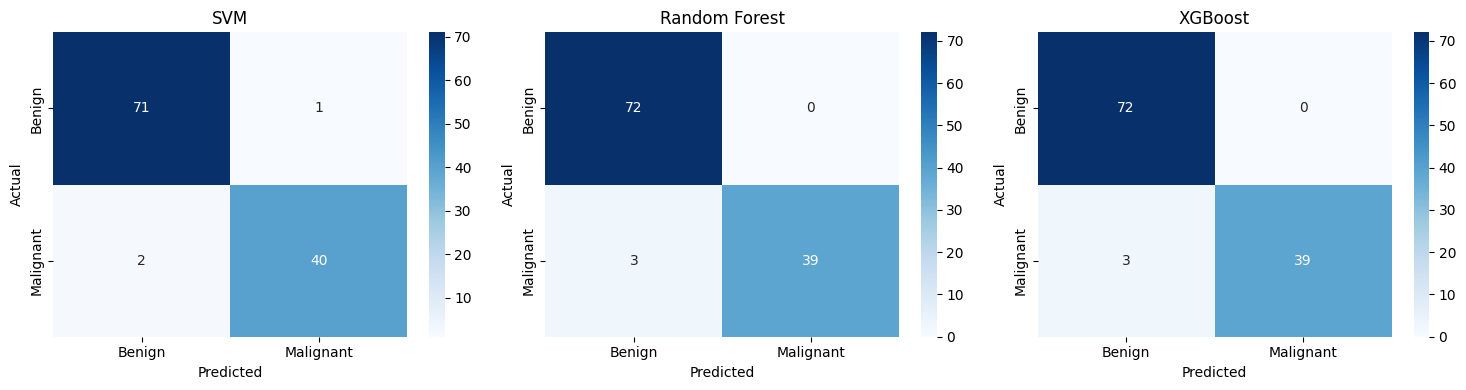

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, model) in zip(axes, best_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    ax.set_title(name)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

##  ROC curves and CV recall comparison

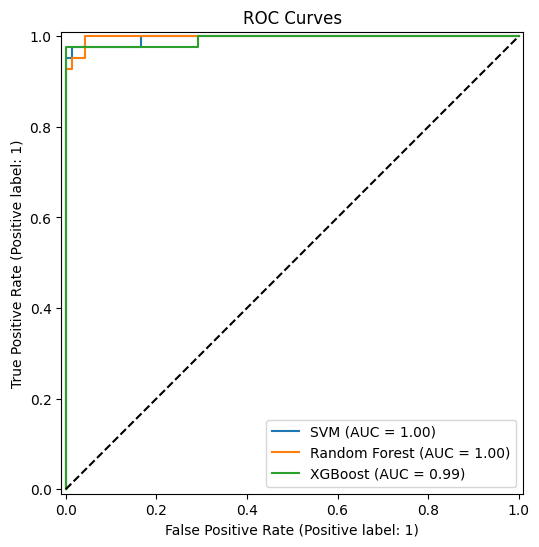

In [18]:
plt.figure(figsize=(7, 6))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=plt.gca())
plt.plot([0,1], [0,1], 'k--')
plt.title('ROC Curves')
plt.show()

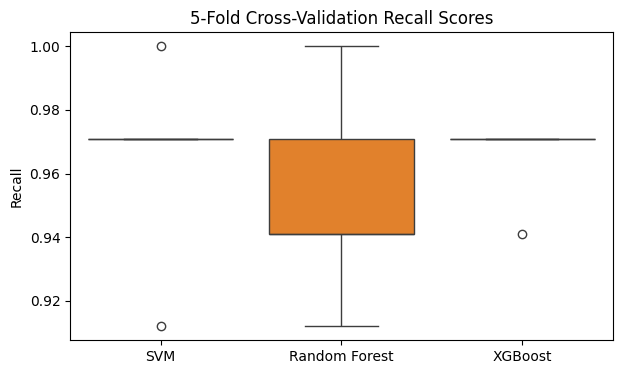

In [19]:
cv_df = pd.DataFrame({r['Model']: r['CV Recall (5 folds)'] for r in results})
plt.figure(figsize=(7, 4))
sns.boxplot(data=cv_df)
plt.title('5-Fold Cross-Validation Recall Scores')
plt.ylabel('Recall')
plt.show()

## BEst model classification report 

In [20]:
best_name = results_df.sort_values('Test Recall', ascending=False).iloc[0]['Model']
best = best_models[best_name]
print("Best model:", best_name)
print(classification_report(y_test, best.predict(X_test), target_names=['Benign', 'Malignant']))

Best model: SVM
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



## reducing threshold to increase the recall

In [21]:
probs = best.predict_proba(X_test)[:, 1]
for t in [0.5, 0.4, 0.3, 0.2]:
    pred = (probs >= t).astype(int)
    print(f"Threshold {t}: Recall = {recall_score(y_test, pred):.3f} | Precision = {precision_score(y_test, pred):.3f}")

Threshold 0.5: Recall = 0.976 | Precision = 0.976
Threshold 0.4: Recall = 0.976 | Precision = 0.953
Threshold 0.3: Recall = 0.976 | Precision = 0.953
Threshold 0.2: Recall = 0.976 | Precision = 0.932


## Conclusion
- The Breast Cancer dataset is imbalanced (37% malignant), so Recall was used as
  the main metric, because missing a cancer case (false negative) is the most
  dangerous error.
- SMOTE was applied inside an imblearn Pipeline, so synthetic samples were created
  only from training folds, which prevents data leakage. Class weighting was tested
  as an alternative.
- SVM, Random Forest and XGBoost were tuned with GridSearchCV using 5-fold
  Stratified Cross-Validation, optimising Recall.
- SVM achieved the best test Recall (~0.95), detecting 40 of 42 malignant cases,
  with high precision (~0.98) and ROC-AUC (~0.99).
- Lowering the decision threshold can increase Recall further, at a small cost
  in precision.